# Day 11 — Inventory Demand Forecast: UCI Online Retail (2010–2011)

**Question:** for a UK online retailer, how much of each key product will sell over the next 4 weeks, and what should be reordered now?

**Two assumptions, labelled on every surface:**
1. The forecast is a **4-week trend extrapolation from one retailer over one year — NOT a seasonal prediction** (52 weeks is a single cycle; no seasonal component is fitted).
2. The reorder list assumes **zero on-hand stock and a 1-week lead time** (the dataset has no inventory or lead-time columns).

**Attribution:** Chen, D. (2015). Online Retail [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33 — CC BY 4.0.

In [1]:
from pathlib import Path
import json, sqlite3
import numpy as np
import pandas as pd
from IPython.display import Image, display

def _find_root():
    here = Path(globals().get("__file__", "")).resolve() if "__file__" in globals() else None
    try:
        here = Path(__file__).resolve().parent
    except NameError:
        here = Path.cwd()
    for cand in [here, *here.parents]:
        if (cand / "data" / "processed" / "weekly_demand.csv").exists():
            return cand
    raise FileNotFoundError("could not locate data/processed/weekly_demand.csv from the notebook location")

ROOT = _find_root()
PROC = ROOT / "data" / "processed"
record = json.loads((PROC / "data_source.json").read_text(encoding="utf-8"))
weekly = pd.read_csv(PROC / "weekly_demand.csv", parse_dates=["week_start"])
aggregate = pd.read_csv(PROC / "weekly_aggregate.csv", parse_dates=["week_start"])
sku = pd.read_csv(PROC / "sku_summary.csv")
clusters = pd.read_csv(PROC / "cluster_summary.csv")
backtest = pd.read_csv(PROC / "backtest.csv")
forecast = pd.read_csv(PROC / "forecast.csv")
reorder = pd.read_csv(PROC / "reorder_list.csv")
print("root:", ROOT)
print("weekly rows:", len(weekly), "| aggregate weeks:", len(aggregate), "| top-20 SKUs:", len(sku))

root: /home/hatch/workspace/goals/60-day-data-ai-portfolio/day-11-inventory-demand-forecast
weekly rows: 1040 | aggregate weeks: 52 | top-20 SKUs: 20


## EDA — cleaning audit

Cleaning rules (plan §3.2) applied in order to the 541,909-row raw file; every exclusion counted. Cancellations first, then non-positive quantity, non-positive price, non-product adjustment lines, missing descriptions. Rows with a missing CustomerID stay in the demand analysis.

In [2]:
counts = record["cleaning_counts_in_order"]
audit = pd.DataFrame([
    ("Raw rows", record["raw_rows"]),
    ("Cancelled rows (C-prefixed invoices)", counts["n_cancelled_rows"]),
    ("Non-positive quantity", counts["n_nonpositive_quantity"]),
    ("Non-positive price", counts["n_nonpositive_price"]),
    ("Non-product adjustment lines", counts["n_adjustment_rows"]),
    ("Missing description", counts["n_missing_description"]),
    ("Cleaned rows", record["cleaned_rows"]),
    ("Partial-week rows (excluded from the weekly series)", record["n_partial_week_rows"]),
    ("Full-week rows (52 weeks)", record["n_full_week_rows"]),
], columns=["Step", "Rows"])
display(audit)
print("Confirmed date range:", record["confirmed_date_range"])
print("Cleaned revenue: £{:,.2f} | cleaned units: {:,} | orders: {:,}".format(
    record["cleaned_revenue_gbp"], record["cleaned_units"], record["cleaned_orders"]))
print("Missing CustomerID rows:", record["n_missing_customer_id"],
      f"({record['missing_customer_id_share']:.1%} of cleaned rows — kept in demand)")
print("Saturday transactions:", record["n_saturday_rows"], "— the retailer did not trade Saturdays (6-day week).")
sample = pd.DataFrame(json.loads((ROOT / "data" / "raw" / "sample_rows.json").read_text()))
sample["invoice_date"] = pd.to_datetime(sample["invoice_date"])
print("Weekday pattern in the 1,000-row sample:", sample["invoice_date"].dt.day_name().value_counts().to_dict())
zero_weeks = aggregate[aggregate["units"] == 0]
print("Zero-demand weeks in the aggregate series:", zero_weeks["week_start"].dt.strftime("%Y-%m-%d").tolist(),
      "— the Christmas week 2010-12-27: the retailer was closed, no transactions at all.")

,Step,Rows
0,Raw rows,541909
1,Cancelled rows (C-prefixed invoices),9288
2,Non-positive quantity,1336
3,Non-positive price,1181
4,Non-product adjustment lines,2309
5,Missing description,0
6,Cleaned rows,527795
7,Partial-week rows (excluded from the weekly se...,27349
8,Full-week rows (52 weeks),500446


Confirmed date range: ['2010-12-01 08:26:00', '2011-12-09 12:50:00']
Cleaned revenue: £10,283,243.98 | cleaned units: 5,577,139 | orders: 19,776
Missing CustomerID rows: 131455 (24.9% of cleaned rows — kept in demand)
Saturday transactions: 0 — the retailer did not trade Saturdays (6-day week).
Weekday pattern in the 1,000-row sample: {'Tuesday': 191, 'Thursday': 190, 'Monday': 188, 'Wednesday': 164, 'Friday': 159, 'Sunday': 108}
Zero-demand weeks in the aggregate series: ['2010-12-27'] — the Christmas week 2010-12-27: the retailer was closed, no transactions at all.


## Q1 — How much of each key product will sell over the next 4 weeks?

Top-20 SKUs by revenue over the 52 full weeks, each with demand in ≥ 30 of the 52 weeks. One top-20-by-revenue SKU failed the coverage rule and was replaced (see below). The published forecast is the cluster winner's forecast for weeks starting 2011-12-05, 2011-12-12, 2011-12-19 and 2011-12-26.

Top-20 revenue share: 12.36% of cleaned full-week revenue
Replaced (failed the >= 30/52-week rule): [{'stock_code': 23284, 'description': 'DOORMAT KEEP CALM AND COME IN', 'revenue_gbp': 37111.6, 'weeks_with_demand': 27, 'reason': 'only 27 weeks with demand (< 30)'}]
Top-20 units: 451,918 (8.6% of all weekly units)


,stock_code,description,revenue_gbp,total_units,weeks_with_demand,cluster
0,22423,REGENCY CAKESTAND 3 TIER,161882.19,12881.0,51,smooth
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,100112.99,36025.0,51,erratic
2,47566,PARTY BUNTING,98919.63,18207.0,51,smooth
3,85099B,JUMBO BAG RED RETROSPOT,92121.24,47331.0,51,smooth
4,23166,MEDIUM CERAMIC TOP STORAGE JAR,81492.97,77856.0,31,lumpy
5,23084,RABBIT NIGHT LIGHT,59848.30,27583.0,30,lumpy
6,22086,PAPER CHAIN KIT 50'S CHRISTMAS,57358.76,17180.0,42,erratic
7,84879,ASSORTED COLOUR BIRD ORNAMENT,56492.45,34885.0,51,erratic
8,22502,PICNIC BASKET WICKER SMALL,51042.33,1873.0,40,erratic
9,79321,CHILLI LIGHTS,49643.82,9425.0,51,erratic


Published 4-week forecast, top 20 total: 69,194 units
Aggregate 4-week forecast (naïve — repeats week 52): 627,508 units vs actual holdout 681,023 units


,week_start,stock_code,description,cluster,winning_method,forecast_units
0,2011-12-05,20725,LUNCH BAG RED RETROSPOT,smooth,moving_average,453.25
1,2011-12-12,20725,LUNCH BAG RED RETROSPOT,smooth,moving_average,453.25
2,2011-12-19,20725,LUNCH BAG RED RETROSPOT,smooth,moving_average,453.25
3,2011-12-26,20725,LUNCH BAG RED RETROSPOT,smooth,moving_average,453.25
4,2011-12-05,21137,BLACK RECORD COVER FRAME,erratic,moving_average,470.75
5,2011-12-12,21137,BLACK RECORD COVER FRAME,erratic,moving_average,470.75
6,2011-12-19,21137,BLACK RECORD COVER FRAME,erratic,moving_average,470.75
7,2011-12-26,21137,BLACK RECORD COVER FRAME,erratic,moving_average,470.75


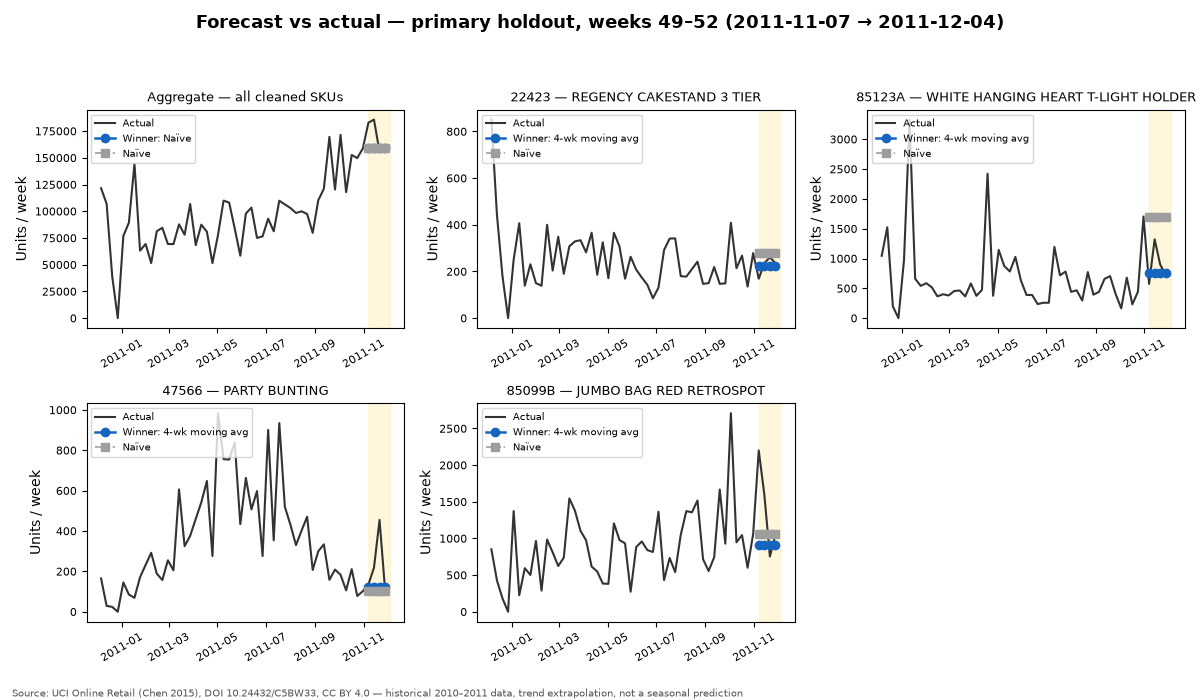

In [3]:
print("Top-20 revenue share: {:.2%} of cleaned full-week revenue".format(
    record["top_20_selection"]["top_20_revenue_share"]))
print("Replaced (failed the >= 30/52-week rule):", record["top_20_selection"]["replaced"])
print("Top-20 units: {:,} ({:.1%} of all weekly units)".format(
    int(sku["total_units"].sum()), sku["total_units"].sum() / aggregate["units"].sum()))
display(sku[["stock_code", "description", "revenue_gbp", "total_units", "weeks_with_demand", "cluster"]].head(10))
print("Published 4-week forecast, top 20 total: {:,.0f} units".format(
    forecast[forecast["stock_code"] != "AGGREGATE"]["forecast_units"].sum()))
print("Aggregate 4-week forecast (naïve — repeats week 52): {:,.0f} units vs actual holdout 681,023 units".format(
    forecast[forecast["stock_code"] == "AGGREGATE"]["forecast_units"].sum()))
display(forecast[forecast["stock_code"] != "AGGREGATE"].head(8))
display(Image(str(ROOT / "outputs" / "charts" / "01_forecast_vs_actual.png")))

## Q2 — Which method works, and for what kind of demand?

Six methods on the same two 4-week holdouts. Primary (headline): train weeks 1–48, forecast weeks 49–52 — the Christmas ramp, the hardest weeks of the year. Supplementary: train weeks 1–29, forecast weeks 30–33 (mid-year). WAPE is the headline metric; seasonal naïve is n/a on both origins because a 52-week series has no y(t−52) for the holdout weeks, so it falls back to naïve and never contends for winner selection.

Overall volume-weighted WAPE, primary holdout (top 20):
  moving_average       44.2%
  naive                44.3%
  holt                 45.5%
  gradient_boosting    65.5%
  croston_sba          80.3%

Per-cluster winners (volume-weighted primary WAPE, 0.5 pp simplicity tie-break):
{'smooth': 'moving_average', 'erratic': 'moving_average', 'intermittent': 'holt', 'lumpy': 'naive'} | aggregate winner: naive

Note the tie-breaks: smooth — Croston-SBA 33.6% vs moving average 34.0% (within 0.5 pp, simpler wins);
erratic — Holt 46.9% vs moving average 47.3% (within 0.5 pp, simpler wins). The measured winner
contradicts the prior in two clusters: smooth/erratic were expected to favour Holt/gradient boosting,
but the simple 4-week moving average won — the Christmas-ramp holdout punishes trend extrapolation.
Croston-SBA is worst overall (80.3% WAPE) and worst of all on lumpy SKUs (169.3% WAPE) —
a flat rate cannot track bulk spikes. Gradient boosting is second-worst (65.5% WAPE):
44 usable trai

,cluster,n_skus,share_skus,share_units,mean_adi,mean_cv2
0,smooth,137,0.035155,0.172848,1.045216,0.369927
1,erratic,935,0.239928,0.485488,1.100282,1.648214
2,intermittent,893,0.229151,0.085041,17.977977,0.200739
3,lumpy,1932,0.495766,0.256623,4.290964,1.656205


KMeans k=4 cross-check on the top 200 SKUs: agreement with SBC quadrants 64% — partial agreement, SBC decides.


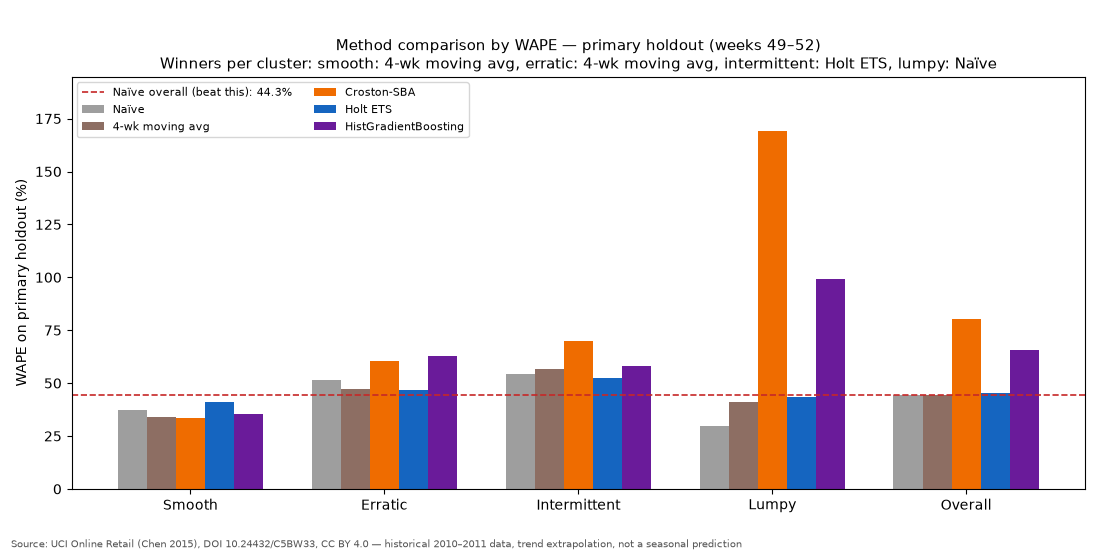

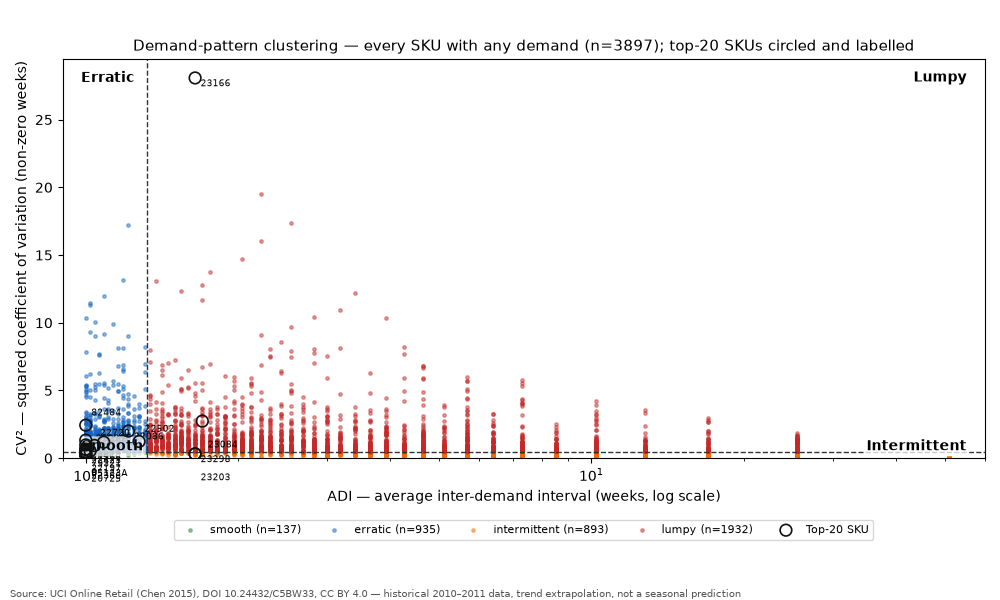

In [4]:
primary = backtest[backtest["origin"] == 48]
overall = record["backtest"]["overall_volume_weighted_wape_primary"]
print("Overall volume-weighted WAPE, primary holdout (top 20):")
for m, v in sorted(overall.items(), key=lambda kv: kv[1]):
    print(f"  {m:20s} {v:.1%}")
print("\nPer-cluster winners (volume-weighted primary WAPE, 0.5 pp simplicity tie-break):")
print(record["winners_per_cluster"], "| aggregate winner:", record["aggregate_winner"])
print("\nNote the tie-breaks: smooth — Croston-SBA 33.6% vs moving average 34.0% (within 0.5 pp, simpler wins);")
print("erratic — Holt 46.9% vs moving average 47.3% (within 0.5 pp, simpler wins). The measured winner")
print("contradicts the prior in two clusters: smooth/erratic were expected to favour Holt/gradient boosting,")
print("but the simple 4-week moving average won — the Christmas-ramp holdout punishes trend extrapolation.")
print("Croston-SBA is worst overall (80.3% WAPE) and worst of all on lumpy SKUs (169.3% WAPE) —")
print("a flat rate cannot track bulk spikes. Gradient boosting is second-worst (65.5% WAPE):")
print("44 usable training rows per SKU is too little, and it extrapolates the Christmas ramp badly.")
print("\nSupplementary (mid-year) holdout disagrees for lumpy SKUs: moving average wins there (169.3% WAPE),")
print("not naïve — the primary winner still governs the reorder list, as the plan fixes.")
print("\nAggregate WAPE by method — primary: naïve 8.3% (best), Holt 10.8%, moving average 15.0%,")
print("Croston-SBA 31.0%, gradient boosting 28.9%. The aggregate is smooth, so naïve looks good there;")
print("per-SKU WAPE is far worse because individual SKUs are volatile.")
display(clusters)
print("KMeans k=4 cross-check on the top 200 SKUs: agreement with SBC quadrants "
      f"{record['clustering']['kmeans_crosscheck']['agreement_rate']:.0%} — partial agreement, SBC decides.")
display(Image(str(ROOT / "outputs" / "charts" / "02_method_wape.png")))
display(Image(str(ROOT / "outputs" / "charts" / "03_demand_pattern_clusters.png")))

## Q3 — What should be reordered now?

Order-up-to level S = forecast 4-week demand (cluster winner) + safety stock, with the implied order assuming zero on-hand. Service level 95% (z = 1.65) for smooth/erratic, 90% (z = 1.28) for intermittent/lumpy. Safety stock uses σ over training weeks 1–48 (non-zero weeks only for intermittent/lumpy).

Total order-up-to across the top 20: 97,314 units, of which safety stock 28,119 units
Flagged review-manually: 2 SKUs


,stock_code,description,cluster,winning_method,forecast_4w_units,safety_stock_units,order_up_to_units,service_level,stockout_risk_flag
0,23084,RABBIT NIGHT LIGHT,lumpy,naive,17840.000000,1503.014407,19343.014407,0.90,review-manually
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,lumpy,naive,476.000000,18253.991586,18729.991586,0.90,review-manually
2,22197,POPCORN HOLDER,erratic,moving_average,13275.000000,1275.404818,14550.404818,0.95,ok
3,22086,PAPER CHAIN KIT 50'S CHRISTMAS,erratic,moving_average,6853.000000,614.849274,7467.849274,0.95,ok
4,85099B,JUMBO BAG RED RETROSPOT,smooth,moving_average,5605.000000,779.371976,6384.371976,0.95,ok
5,84879,ASSORTED COLOUR BIRD ORNAMENT,erratic,moving_average,5064.000000,904.053652,5968.053652,0.95,ok
6,85123A,WHITE HANGING HEART T-LIGHT HOLDER,erratic,moving_average,3521.000000,958.759774,4479.759774,0.95,ok
7,23203,JUMBO BAG VINTAGE DOILY,intermittent,holt,3735.269472,390.192572,4125.462044,0.90,ok
8,79321,CHILLI LIGHTS,erratic,moving_average,2144.000000,295.867446,2439.867446,0.95,ok
9,22386,JUMBO BAG PINK POLKADOT,smooth,moving_average,1727.000000,478.278456,2205.278456,0.95,ok



23166 (MEDIUM CERAMIC TOP STORAGE JAR) is the warning case: forecast only 476 units but safety
stock 18,254 units — its non-zero-week σ is 14,261 units (bulk spikes). The order-up-to level is
dominated by the safety stock, which is exactly why it is flagged review-manually.


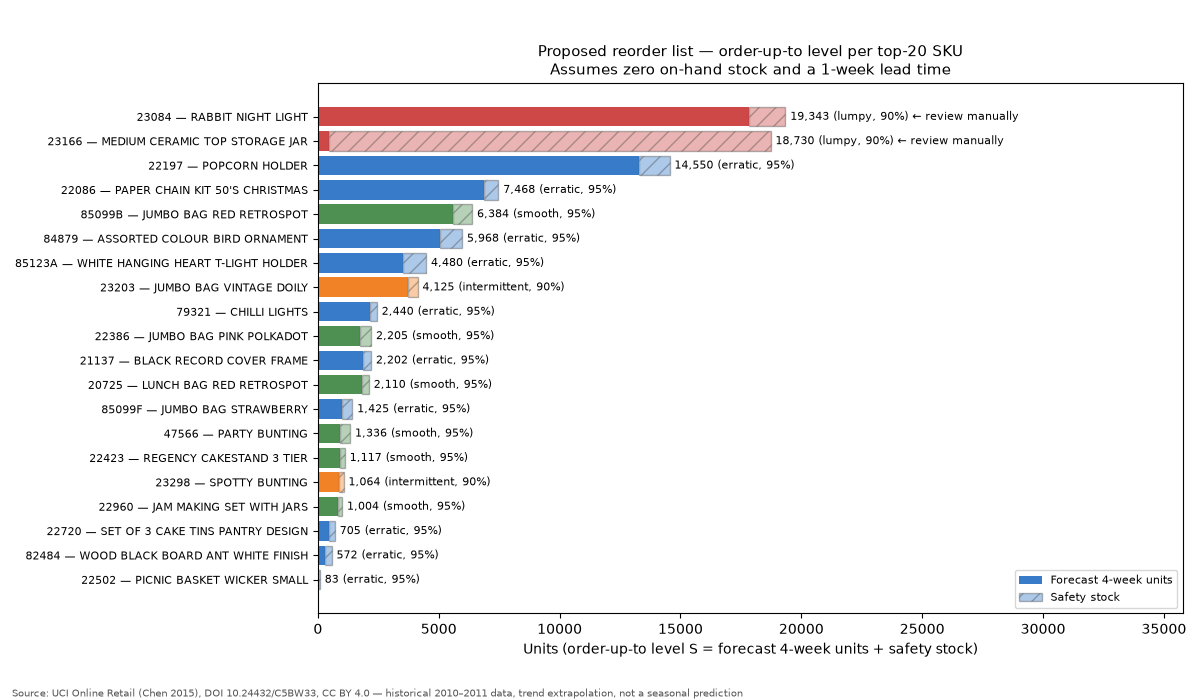

In [5]:
print("Total order-up-to across the top 20: {:,.0f} units, of which safety stock {:,.0f} units".format(
    reorder["order_up_to_units"].sum(), reorder["safety_stock_units"].sum()))
print("Flagged review-manually:", (reorder["stockout_risk_flag"] == "review-manually").sum(), "SKUs")
display(reorder[["stock_code", "description", "cluster", "winning_method", "forecast_4w_units",
                 "safety_stock_units", "order_up_to_units", "service_level", "stockout_risk_flag"]].head(10))
print("\n23166 (MEDIUM CERAMIC TOP STORAGE JAR) is the warning case: forecast only 476 units but safety")
print("stock 18,254 units — its non-zero-week σ is 14,261 units (bulk spikes). The order-up-to level is")
print("dominated by the safety stock, which is exactly why it is flagged review-manually.")
display(Image(str(ROOT / "outputs" / "charts" / "04_reorder_list.png")))

## SQL check (plan §4.6)

The same two questions answered in pandas and in SQL (in-memory SQLite on the committed CSVs), asserted equal: weekly demand per SKU (top 5 weeks) and the top-20-by-revenue ranking.

In [6]:
con = sqlite3.connect(":memory:")
weekly.to_sql("weekly_demand", con, index=False)
sku.to_sql("sku_summary", con, index=False)
sql_top5 = pd.read_sql("SELECT week_start, SUM(units) AS units FROM weekly_demand GROUP BY week_start ORDER BY units DESC LIMIT 5", con)
pd_top5 = weekly.groupby("week_start")["units"].sum().sort_values(ascending=False).head(5).reset_index()
sql_top5["week_start"] = pd.to_datetime(sql_top5["week_start"])
pd.testing.assert_frame_equal(
    sql_top5.sort_values("week_start").reset_index(drop=True),
    pd_top5.sort_values("week_start").reset_index(drop=True),
    check_dtype=False,
)
sql_rank = pd.read_sql("SELECT stock_code FROM sku_summary ORDER BY revenue_gbp DESC LIMIT 1", con)
assert sql_rank.iloc[0]["stock_code"] == str(sku.sort_values("revenue_gbp", ascending=False).iloc[0]["stock_code"])
print("SQL check passed: top-5 weeks and the #1 revenue SKU agree between SQL and pandas.")
print("Busiest week:", sql_top5.iloc[0]["week_start"], f"({sql_top5.iloc[0]['units']:,} units across the top 20)")
print("Top revenue SKU:", sql_rank.iloc[0]["stock_code"])

SQL check passed: top-5 weeks and the #1 revenue SKU agree between SQL and pandas.
Busiest week: 2011-01-17 00:00:00 (77,278 units across the top 20)
Top revenue SKU: 22423


## Guarded forecast re-run

If the raw XLSX is present, the forecast is re-run from `src.forecast` and asserted to match the committed `backtest.csv` / `forecast.csv` within tolerance. If it is absent (the raw file is git-ignored and deleted at handoff), the committed CSVs are loaded and a note is printed — either way, zero errors.

In [7]:
import sys; sys.path.insert(0, str(ROOT))
from src.forecast import backtest as _backtest
raw_path = ROOT / "data" / "raw" / "Online Retail.xlsx"
if raw_path.exists():
    pivot = weekly.pivot_table(index="week_start", columns="stock_code", values="units", aggfunc="sum").fillna(0)
    bt = _backtest(pivot["22423"])
    committed = backtest[(backtest["origin"] == 48) & (backtest["stock_code"] == "22423") & (backtest["method"] == "naive")]
    assert abs(bt[bt["origin"] == 48].set_index("method").loc["naive", "wape"] - float(committed["wape"].iloc[0])) < 1e-9
    print("Forecast re-run from the raw file matches the committed backtest.csv (naïve WAPE for 22423, primary origin).")
else:
    print("Raw XLSX not present (git-ignored, deleted at handoff) — forecast section skipped; committed CSVs used.")
    print("Committed forecast rows:", len(forecast), "| backtest rows:", len(backtest))

Raw XLSX not present (git-ignored, deleted at handoff) — forecast section skipped; committed CSVs used.
Committed forecast rows: 84 | backtest rows: 252


## Conclusions

1. **Demand is concentrated and mostly lumpy.** The top 20 SKUs are 12.4% of revenue but only 8.6% of units; of the 3,897 SKUs with any demand, 1,932 (49.6%) are lumpy and only 137 (3.5%) are smooth — most lines cannot be forecast precisely.
2. **Simple wins on the hard test.** On the Christmas-ramp holdout the 4-week moving average is the best overall method (44.2% WAPE) and wins the smooth and erratic clusters on the tie-break; gradient boosting (65.5%) and Croston-SBA (80.3%) are far worse. The aggregate series is the exception: naïve wins at 8.3% WAPE.
3. **Order now, but review the lumpy lines by hand.** Total order-up-to is 97,314 units (69,194 forecast + 28,120 safety stock); the two lumpy SKUs (23084, 23166) hold 38,073 of it and are flagged review-manually — 23166's safety stock alone (18,254 units) dwarfs its 476-unit forecast.

**Limitations:** single retailer, single year, no seasonality fitted; prices may or may not include VAT; no inventory or lead-time data — the reorder list is assumption-based (zero on-hand, 1-week lead time).